<a href="https://colab.research.google.com/github/Epot12/QML_project/blob/master/QML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#QML PROJECT

In [2]:
!pip install pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 26.9 MB/s eta 0:00:00


In [7]:
import os
import shutil
from google.colab import drive
import torch
import torch.nn as nn
import pandas as pd
import pydicom
import glob
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision.models import swin_b, Swin_B_Weights

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##Exploratory Data Analysis INbreast

In [11]:
zip_path = '/content/drive/MyDrive/QML/INbreast/INbreast.zip'

# estrazione zip nella memoria temporanea di Colab, NON su Drive
# Questo percorso è veloce e si cancella alla chiusura di Colab
extract_path = '/content/data/INbreast_extracted'

print(f"File ZIP sorgente: {zip_path}")
print(f"Cartella di destinazione: {extract_path}")

# Estrazione (Unzip)
if not os.path.exists(extract_path):
    print("Estrazione in corso...")
    # Creo la cartella
    os.makedirs(extract_path, exist_ok=True)

    # Estraggo lo zip
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Estrazione completata!")
else:
    print("Dataset già estratto, procedo.")

# Ora cerco i DICOM nella cartella ESTRATTA (non nello zip)
dataset_root = extract_path  # punta alla cartella aperta!

print(f"Analisi del percorso: {dataset_root}")

dicom_files = []
for root, dirs, files in os.walk(dataset_root):
    for file in files:
        # AGGIUNTO: .roi e .m alla lista delle esclusioni
        if not file.startswith('.') and not file.endswith(('.xls', '.xlsx', '.csv', '.xml', '.txt', '.zip', '.roi', '.m')):
             dicom_files.append(os.path.join(root, file))

print(f"🎉 Trovati {len(dicom_files)} potenziali file DICOM.")

# 4. Estrazione Metadati
data_list = []
print("Lettura metadati DICOM in corso...")

for file_path in dicom_files:
    try:
        ds = pydicom.dcmread(file_path, stop_before_pixels=True)

        # Recupera il valore grezzo dal DICOM
        pid_dicom = ds.get('PatientID', '')

        # Logica di correzione: Se è "Unknown", vuoto o None, usa il nome del file
        filename = os.path.basename(file_path)
        if str(pid_dicom).strip() in ['Unknown', '', 'None']:
            # Pulisce il nome file da estensioni o caratteri extra
            clean_pid = filename.split('_')[0].replace('.dcm', '')
            final_patient_id = clean_pid
        else:
            final_patient_id = pid_dicom

        data_list.append({
            'file_path': file_path,
            'PatientID': final_patient_id,  # Usa il valore corretto calcolato sopra
            'Laterality': ds.get('ImageLaterality', 'Unknown'),
            'ViewPosition': ds.get('ViewPosition', 'Unknown'),
            'Rows': ds.get('Rows', 0),
            'Columns': ds.get('Columns', 0)
        })
    except Exception as e:
        print(f"Errore su {file_path}: {e}")
        continue

df_images = pd.DataFrame(data_list)
print(f"Fatto! Dimensioni dataset: {df_images.shape}")
display(df_images.head())

File ZIP sorgente: /content/drive/MyDrive/QML/INbreast/INbreast.zip
Cartella di destinazione: /content/data/INbreast_extracted
Dataset già estratto, procedo.
Analisi del percorso: /content/data/INbreast_extracted
🎉 Trovati 411 potenziali file DICOM.
Lettura metadati DICOM in corso...
Errore su /content/data/INbreast_extracted/INbreast/INbreast Release 1.0/inbreast.pdf: File is missing DICOM File Meta Information header or the 'DICM' prefix is missing from the header. Use force=True to force reading.
Fatto! Dimensioni dataset: (410, 6)


,file_path,PatientID,Laterality,ViewPosition,Rows,Columns
0,/content/data/INbreast_extracted/INbreast/INbr...,53582540,Unknown,Unknown,3328,2560
1,/content/data/INbreast_extracted/INbreast/INbr...,53581941,Unknown,Unknown,3328,2560
2,/content/data/INbreast_extracted/INbreast/INbr...,51049489,Unknown,Unknown,3328,2560
3,/content/data/INbreast_extracted/INbreast/INbr...,50996999,Unknown,Unknown,4084,3328
4,/content/data/INbreast_extracted/INbreast/INbr...,53581433,Unknown,Unknown,3328,2560


Nel codice seguente si verifica se esistono degli split predefiniti. Inoltre vengono cercate le diagnosi.

In [12]:
# Cerca il file Excel con le diagnosi (BI-RADS)
xls_files = glob.glob(os.path.join(dataset_root, '**/*.xls*'), recursive=True)
csv_files = glob.glob(os.path.join(dataset_root, '**/*.csv'), recursive=True)

# Uniamo le liste
candidates = xls_files + csv_files

# --- FILTRO DI SICUREZZA (Nuovo!) ---
# Ignoriamo file che iniziano con '._' (Mac) o '~$' (File aperti di Windows)
metadata_files = [f for f in candidates if not os.path.basename(f).startswith(('._', '~$'))]

print("\n--- ANALISI FEATURES E LABELS ---")
if metadata_files:
    # Prendiamo il primo file valido trovato
    meta_path = metadata_files[0]
    print(f"📄 Trovato file di metadati/label: {meta_path}")

    # Carica a seconda del formato
    try:
        if meta_path.endswith('.csv'):
            # Proviamo con ; che è standard INbreast, se fallisce pandas ci avvisa
            df_labels = pd.read_csv(meta_path, sep=';')
            if df_labels.shape[1] < 2: # Se ha letto tutto in una colonna sola, riprova con la virgola
                print("⚠️ Separatore ';' non valido, riprovo con ','")
                df_labels = pd.read_csv(meta_path, sep=',')
        else:
            df_labels = pd.read_excel(meta_path)

        print("✅ File caricato con successo!")
        print("Prime righe del file Labels:")
        display(df_labels.head())
        print("\n📊 Colonne disponibili (Features):")
        print(df_labels.columns.tolist())

    except Exception as e:
        print(f"❌ Errore nella lettura del file Excel: {e}")

else:
    print("⚠️ ATTENZIONE: Nessun file Excel/CSV valido trovato.")
    print("Controlla se il file 'INbreast.xls' è presente nello zip.")

# NOTA: Ho rimosso temporaneamente i grafici.
# Farai i grafici DOPO aver unito (merge) questo df_labels con df_images.


--- ANALISI FEATURES E LABELS ---
📄 Trovato file di metadati/label: /content/data/INbreast_extracted/INbreast/INbreast Release 1.0/INbreast.xls
✅ File caricato con successo!
Prime righe del file Labels:


,Patient ID,Patient age,Laterality,View,Acquisition date,File Name,ACR,Bi-Rads,Mass,Micros,Distortion,Asymmetry,Findings Notes (in Portuguese),Other Notes,Lesion Annotation Status,Pectoral Muscle Annotation,Other Annotations
0,removed,removed,R,CC,201001.0,22678622.0,4,1,NaN,NaN,NaN,NaN,normal,NaN,No annotation (Normal),NaN,NaN
1,removed,removed,L,CC,201001.0,22678646.0,4,3,X,NaN,NaN,NaN,nódulo,NaN,NaN,NaN,NaN
2,removed,removed,R,MLO,201001.0,22678670.0,4,1,NaN,NaN,NaN,NaN,normal,NaN,No annotation (Normal),NaN,NaN
3,removed,removed,L,MLO,201001.0,22678694.0,4,3,X,NaN,NaN,NaN,nódulo,NaN,NaN,NaN,NaN
4,removed,removed,R,CC,201001.0,22614074.0,2,5,X,X,NaN,NaN,nódulo QSE + micros,NaN,NaN,NaN,NaN



📊 Colonne disponibili (Features):
['Patient ID', 'Patient age', 'Laterality', 'View', 'Acquisition date', 'File Name', 'ACR', 'Bi-Rads', 'Mass ', 'Micros', 'Distortion', 'Asymmetry', 'Findings Notes (in Portuguese)', 'Other Notes', 'Lesion Annotation Status', 'Pectoral Muscle Annotation', 'Other Annotations']


In [13]:
# --- STEP 5: MERGE (UNIONE) DELLE TABELLE ---

# 1. Pulizia della chiave nel file Excel (df_labels)
# Convertiamo la colonna 'File Name' in stringa e togliamo il ".0" finale se c'è
# (perché nel DICOM abbiamo "22614074", qui "22614074.0")
df_labels['File Name'] = df_labels['File Name'].astype(str).str.replace('.0', '', regex=False)

# 2. Pulizia della chiave nel DataFrame Immagini (df_images)
# Assicuriamoci che anche qui sia una stringa pulita
df_images['PatientID'] = df_images['PatientID'].astype(str).str.strip()

# 3. Eseguiamo il Merge
# Uniamo "Left" (teniamo tutte le immagini) con "Right" (l'Excel)
# Chiave Immagini: 'PatientID' <--> Chiave Excel: 'File Name'
df_final = pd.merge(df_images, df_labels, left_on='PatientID', right_on='File Name', how='left')

# 4. Riempiamo i campi "Unknown" usando i dati dell'Excel
# Se Laterality era Unknown, prendi quella dell'Excel
df_final['Laterality'] = df_final['Laterality_x'].where(df_final['Laterality_x'] != 'Unknown', df_final['Laterality_y'])
df_final['ViewPosition'] = df_final['ViewPosition'].where(df_final['ViewPosition'] != 'Unknown', df_final['View'])

# 5. Pulizia finale colonne doppie
columns_to_keep = ['file_path', 'PatientID', 'Bi-Rads', 'Laterality', 'ViewPosition', 'Rows', 'Columns']
df_final = df_final[columns_to_keep]

print("✅ Merge completato!")
print(f"Dimensioni finali: {df_final.shape}")
print("Esempio dati finali:")
display(df_final.head())

# Controllo quanti hanno il Bi-Rads (se qualcuno è NaN c'è stato un problema di match)
missing = df_final['Bi-Rads'].isna().sum()
print(f"\n⚠️ Immagini senza etichetta Bi-Rads trovata: {missing}")

✅ Merge completato!
Dimensioni finali: (410, 7)
Esempio dati finali:


,file_path,PatientID,Bi-Rads,Laterality,ViewPosition,Rows,Columns
0,/content/data/INbreast_extracted/INbreast/INbr...,53582540,1,R,MLO,3328,2560
1,/content/data/INbreast_extracted/INbreast/INbr...,53581941,2,R,CC,3328,2560
2,/content/data/INbreast_extracted/INbreast/INbr...,51049489,2,R,MLO,3328,2560
3,/content/data/INbreast_extracted/INbreast/INbr...,50996999,2,L,CC,4084,3328
4,/content/data/INbreast_extracted/INbreast/INbr...,53581433,1,L,CC,3328,2560



⚠️ Immagini senza etichetta Bi-Rads trovata: 0


✅ Conversione completata!
Distribuzione Classi:
Label
0    310
1    100
Name: count, dtype: int64


/tmp/ipython-input-786881577.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Label', data=df_final, palette=['green', 'red'])


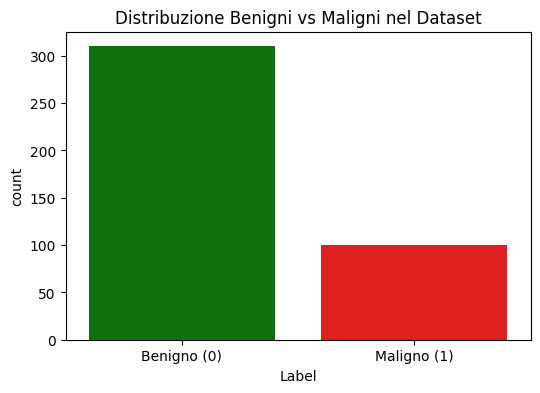

In [14]:
# --- STEP 6: CONVERSIONE IN CLASSI BINARIE ---

def mappa_birads(valore):
    # Convertiamo in intero (gestisce anche stringhe tipo '4a', '4b' se ce ne fossero)
    try:
        v = int(str(valore)[0]) # Prende solo la prima cifra (es '4a' -> 4)
    except:
        return None # Gestione errori

    if v in [1, 2, 3]:
        return 0 # Classe BENIGNO
    elif v in [4, 5, 6]:
        return 1 # Classe MALIGNO
    else:
        return None # BI-RADS 0 o errori

# Applichiamo la funzione
df_final['Label'] = df_final['Bi-Rads'].apply(mappa_birads)

# Rimuoviamo eventuali righe che non siamo riusciti a classificare
df_final = df_final.dropna(subset=['Label'])
df_final['Label'] = df_final['Label'].astype(int)

# Visualizziamo la distribuzione
print("✅ Conversione completata!")
print("Distribuzione Classi:")
print(df_final['Label'].value_counts())

# Grafico per vedere se è bilanciato
plt.figure(figsize=(6, 4))
sns.countplot(x='Label', data=df_final, palette=['green', 'red'])
plt.xticks([0, 1], ['Benigno (0)', 'Maligno (1)'])
plt.title('Distribuzione Benigni vs Maligni nel Dataset')
plt.show()

In [15]:
print("🔍 Cerco un file .roi di esempio...")

roi_files_found = []
# Cerca ricorsivamente nella cartella estratta
for root, dirs, files in os.walk('/content/data/INbreast_extracted'):
    for file in files:
        if file.endswith('.roi'):
            roi_files_found.append(os.path.join(root, file))

if roi_files_found:
    sample_roi = roi_files_found[0]
    print(f"📄 Trovato: {sample_roi}")
    print("-" * 30)
    print("CONTENUTO DEL FILE (Primi 500 caratteri):")
    print("-" * 30)

    try:
        # Proviamo a leggerlo come testo
        with open(sample_roi, 'r', encoding='utf-8', errors='replace') as f:
            content = f.read(500)
            print(content)
    except Exception as e:
        print(f"❌ Impossibile leggere il file come testo: {e}")

    print("-" * 30)
else:
    print("⚠️ Nessun file .roi trovato nelle cartelle estratte!")

🔍 Cerco un file .roi di esempio...
📄 Trovato: /content/data/INbreast_extracted/INbreast/INbreast Release 1.0/PectoralMuscle/Pectoral Muscle ROI/50998440_muscle.roi
------------------------------
CONTENUTO DEL FILE (Primi 500 caratteri):
------------------------------
streamtyped���@���NSMutableArray ��NSArray ��NSObject ��i����ROI���������MyPoint �����NSString��+{2759.05, 6.62378}���������{2779.96, 53.4911}���������{2798.42, 117.778}���������{2810, 177.986}���������{2821.57, 247.457}���������{2835.47, 312.297}���������{2847.05, 384.084}���������{2860.94, 460.502}���������{2874.84, 529.974}���������{2891.05, 617.971}���������{2904.94, 689.758}���������{2921.15, 761.545}���������{2946.62, 861.12}���������{2976.73, 942.17}���������
------------------------------


In [16]:
import re
import numpy as np
import cv2 # OpenCV per il ridimensionamento
from google.colab.patches import cv2_imshow # Per vedere le immagini su Colab

# --- FUNZIONE 1: PARSER DEL FILE .ROI (Il "Decodificatore") ---
def parse_roi_file(roi_path):
    """
    Legge un file .roi di INbreast e restituisce una lista di coordinate (x, y).
    Usa Regex per trovare i pattern {numero, numero}.
    """
    try:
        with open(roi_path, 'r', encoding='utf-8', errors='ignore') as f:
            content = f.read()

        # Questa regex cerca pattern tipo {1234.56, 789.10}
        # Spiegazione regex: \{ = parentesi graffa aperta, ([0-9.]+) = cattura numero
        points_str = re.findall(r'\{([0-9.]+),\s*([0-9.]+)\}', content)

        points = []
        for p in points_str:
            x, y = float(p[0]), float(p[1])
            points.append([x, y])

        return np.array(points)
    except Exception as e:
        print(f"Errore lettura ROI {roi_path}: {e}")
        return None

# --- FUNZIONE 2: PRENDI IL QUADRATO (Bounding Box) ---
def get_bounding_box(points, img_shape):
    """
    Dai punti del contorno, calcola il rettangolo (min_x, min_y, max_x, max_y).
    Aggiunge un piccolo margine (padding) per non tagliare il bordo del tumore.
    """
    if points is None or len(points) == 0:
        return None

    # Coordinate minime e massime
    min_x = np.min(points[:, 0])
    max_x = np.max(points[:, 0])
    min_y = np.min(points[:, 1])
    max_y = np.max(points[:, 1])

    # Aggiungiamo un margine del 10% (Padding)
    width = max_x - min_x
    height = max_y - min_y
    margin = int(max(width, height) * 0.1)

    # Coordinate finali (facendo attenzione a non uscire dall'immagine)
    x1 = int(max(0, min_x - margin))
    y1 = int(max(0, min_y - margin))
    x2 = int(min(img_shape[1], max_x + margin))
    y2 = int(min(img_shape[0], max_y + margin))

    return (x1, y1, x2, y2)

# --- FUNZIONE 3: ELABORAZIONE COMPLETA (Crop + Resize) ---
def process_single_case(dicom_path, roi_path_list):
    """
    Prende un DICOM e una lista di ROI possibili.
    Ritaglia la lesione e la ridimensiona a 224x224.
    """
    # 1. Carica Immagine DICOM
    ds = pydicom.dcmread(dicom_path)
    img = ds.pixel_array

    # Normalizzazione base per visualizzazione (0-255)
    img_norm = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    # 2. Cerca la ROI giusta (ignorando i muscoli)
    lesion_points = None
    used_roi_path = None

    for r_path in roi_path_list:
        if "muscle" in r_path.lower() or "pectoral" in r_path.lower():
            continue # Ignora i muscoli

        points = parse_roi_file(r_path)
        if points is not None and len(points) > 3: # Almeno un triangolo
            lesion_points = points
            used_roi_path = r_path
            break # Trovata una lesione! (Prendiamo la prima valida)

    # 3. Se non c'è ROI (es. caso Benigno sano), prendiamo il centro o tutta l'immagine?
    # Il paper dice che usano solo casi CON ROI. Se non c'è ROI, questo caso andrebbe scartato per la riproduzione fedele.
    if lesion_points is None:
        return None, None # Nessuna lesione trovata

    # 4. Calcola Bounding Box e Ritaglia
    bbox = get_bounding_box(lesion_points, img.shape)
    if bbox is None: return None, None

    x1, y1, x2, y2 = bbox
    img_cropped = img_norm[y1:y2, x1:x2] # RITAGLIO CHIRURGICO

    # 5. Resize per Swin Transformer (224x224)
    # Usiamo INTER_CUBIC che è meglio per l'imaging medico
    img_final = cv2.resize(img_cropped, (224, 224), interpolation=cv2.INTER_CUBIC)

    return img_final, used_roi_path

🔬 Test del sistema di ritaglio su un caso Maligno...
Paziente Test: 22580038
Trovati 1 file ROI candidati.
✅ Successo! ROI usata: 22580038.roi


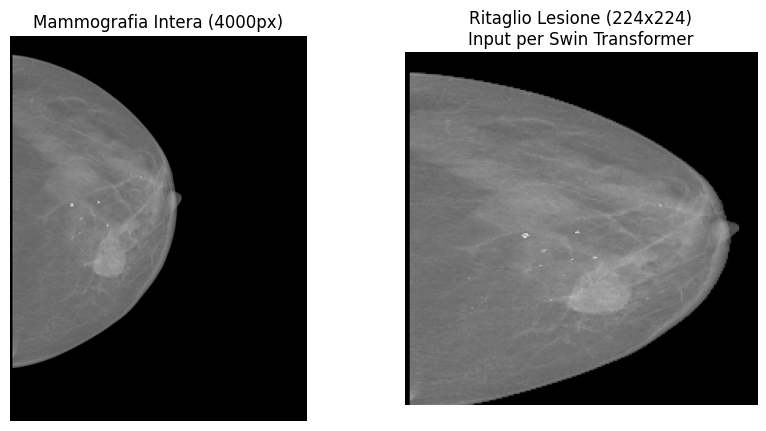

In [17]:
# --- TEST VISIVO ---
print("🔬 Test del sistema di ritaglio su un caso Maligno...")

# 1. Trova tutti i file ROI nel sistema
all_rois = []
for root, dirs, files in os.walk('/content/data/INbreast_extracted'):
    for file in files:
        if file.endswith('.roi'):
            all_rois.append(os.path.join(root, file))

# 2. Prendi un caso Maligno (Bi-Rads 4, 5, 6 -> Label 1)
malignant_cases = df_final[df_final['Label'] == 1]

if not malignant_cases.empty:
    # Ne prendiamo uno a caso
    sample = malignant_cases.iloc[0]
    pid = sample['PatientID']
    dcm_path = sample['file_path']

    print(f"Paziente Test: {pid}")

    # 3. Cerca i file ROI che appartengono a questo paziente
    # (Il nome del file ROI di solito contiene l'ID del paziente)
    patient_rois = [r for r in all_rois if str(pid) in r]

    if patient_rois:
        print(f"Trovati {len(patient_rois)} file ROI candidati.")

        # 4. PROVA IL RITAGLIO
        cropped_img, roi_used = process_single_case(dcm_path, patient_rois)

        if cropped_img is not None:
            print(f"✅ Successo! ROI usata: {os.path.basename(roi_used)}")

            plt.figure(figsize=(10, 5))

            # Mostra originale (ridimensionata per display)
            ds = pydicom.dcmread(dcm_path)
            plt.subplot(1, 2, 1)
            plt.imshow(ds.pixel_array, cmap='gray')
            plt.title("Mammografia Intera (4000px)")
            plt.axis('off')

            # Mostra il ritaglio
            plt.subplot(1, 2, 2)
            plt.imshow(cropped_img, cmap='gray')
            plt.title("Ritaglio Lesione (224x224)\nInput per Swin Transformer")
            plt.axis('off')

            plt.show()
        else:
            print("❌ Trovati file ROI ma nessuno era una lesione valida (forse solo muscoli?).")
    else:
        print("⚠️ Nessun file ROI trovato per questo paziente maligno.")
else:
    print("Nessun caso maligno nel dataframe?!")

### Swin B Transformer classico

In [ ]:
weights = Swin_B_Weights.IMAGENET1K_V1
model = swin_b(weights=weights)

In [ ]:
for param in model.parameters():
    param.requires_grad = True

num_features = model.head.in_features

In [ ]:
model.head = nn.Sequential(
    nn.Linear(num_features, 1024),
    nn.ReLU(),
    nn.Linear(1024, 16),
    nn.Linear(16, 2)
)